# Tugas 3 — Data Preprocessing UNSW-NB15
### Klasifikasi Trafik Jaringan: Normal (0) vs Attack (1)

**Tujuan:** menyiapkan data UNSW-NB15 dari tahap EDA agar siap digunakan untuk *modelling* dan evaluasi. Notebook ini **berdiri sendiri**, sehingga dapat dijalankan dari awal di **Google Colab** atau **Kaggle Notebook**.

**Alur:** impor dataset → audit kualitas data → pemisahan train/validation/test → seleksi fitur → penanganan nilai hilang → *one-hot encoding* → standardisasi numerik → verifikasi → ekspor hasil.

> **Penting:** Preprocessing secara metodologis dilakukan **sebelum** modelling. Semua statistik imputasi, skala, dan kategori encoder dipelajari **hanya pada data training** agar tidak terjadi *data leakage*. Seluruh angka hasil pada notebook muncul dari eksekusi, bukan contoh angka yang diklaim sebagai hasil.

## A. Persiapan dan pengaturan

- Sumber default adalah dataset Kaggle `darkn3t/unsw-nb15-training-set-csv` yang digunakan pada tugas sebelumnya.
- Di Kaggle, folder `/kaggle/input/...` dapat dipakai jika dataset telah ditambahkan ke notebook.
- Di Google Colab, `kagglehub` akan mengunduh dataset ke folder yang ditentukan KaggleHub.
- Jika akses unduhan gagal, ganti `DATA_SOURCE` menjadi `manual`, kemudian gunakan folder berisi CSV yang sudah diunggah.

Notebook tidak memerlukan GPU; CPU Colab umumnya memadai.

In [1]:
import sys, json, warnings, shutil, subprocess
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn

RANDOM_STATE = 42
DATA_SOURCE = "kaggle"  # "kaggle" atau "manual"
KAGGLE_HANDLE = "darkn3t/unsw-nb15-training-set-csv"
KAGGLE_INPUT_PATH = Path("/kaggle/input/datasets/darkn3t/unsw-nb15-training-set-csv")
MANUAL_DATA_DIR = Path("/content")  # ubah apabila CSV tersimpan di Drive/folder lain

WORK_DIR = Path("/content") if Path("/content").is_dir() else (Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd())
OUTPUT_DIR = WORK_DIR / "Hasil_Preprocessing_UNSW_NB15"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_TRANSFORMED_DATA = True  # simpan matriks sparse .npz untuk modelling
CREATE_ZIP = True

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Folder output:", OUTPUT_DIR)

Python: 3.13.16 | pandas: 2.2.3 | scikit-learn: 1.6.1
Folder output: /content/Hasil_Preprocessing_UNSW_NB15


## B. Memuat dataset CSV

Jika ada **training-set dan testing-set**, keduanya dipertahankan sebagai pemisahan resmi. Jika hanya ada **satu CSV**, data dibagi menggunakan `train_test_split` secara *stratified*.

Nama file dicek otomatis; periksa output `TRAIN_FILE` dan `TEST_FILE` sebelum melanjutkan. Jangan gunakan file `attack_cat` sebagai target apabila tugasnya klasifikasi biner: target yang digunakan adalah `label`.

In [2]:
if DATA_SOURCE == "kaggle":
    candidates = [
        KAGGLE_INPUT_PATH,
        Path("/kaggle/input/unsw-nb15-training-set-csv"),
    ]
    existing = [p for p in candidates if p.is_dir()]
    if existing:
        dataset_root = existing[0]
        print("Dataset ditemukan di Kaggle:", dataset_root)
    else:
        try:
            import kagglehub
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        try:
            dataset_root = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        except Exception as exc:
            raise RuntimeError(
                "Gagal mengambil dataset dari Kaggle. Periksa koneksi internet / akses dataset, "
                "atau unggah CSV dan ubah DATA_SOURCE='manual'."
            ) from exc
        print("Dataset diunduh ke:", dataset_root)
elif DATA_SOURCE == "manual":
    dataset_root = MANUAL_DATA_DIR
    if not dataset_root.is_dir():
        raise FileNotFoundError(f"Folder manual tidak ditemukan: {dataset_root}")
else:
    raise ValueError("DATA_SOURCE harus 'kaggle' atau 'manual'.")

csv_files = sorted(p for p in dataset_root.rglob("*.csv") if p.is_file() and OUTPUT_DIR not in p.parents)
print("\nCSV yang ditemukan:")
for p in csv_files:
    print(" -", p.relative_to(dataset_root), f"({p.stat().st_size/1e6:.2f} MB)")
if not csv_files:
    raise FileNotFoundError("Tidak ada CSV pada folder sumber. Unggah dataset atau periksa path.")

def normalized_filename(path):
    return path.stem.lower().replace("_", "").replace("-", "").replace(" ", "")

train_candidates = [p for p in csv_files if "train" in normalized_filename(p)]
test_candidates = [p for p in csv_files if "test" in normalized_filename(p)]
if len(train_candidates) != 1 or len(test_candidates) > 1:
    if len(csv_files) == 1:
        train_candidates = [csv_files[0]]
        test_candidates = []
    else:
        raise ValueError(
            "Pemilihan file ambigu. Pastikan hanya ada satu training CSV dan maksimal satu testing CSV "
            "di folder sumber, lalu jalankan ulang.\n" + "\n".join(str(p) for p in csv_files)
        )
TRAIN_FILE = train_candidates[0]
TEST_FILE = test_candidates[0] if test_candidates else None
print("\nTRAIN_FILE:", TRAIN_FILE)
print("TEST_FILE :", TEST_FILE if TEST_FILE else "Tidak ada (holdout stratified akan dibuat)")

100%|██████████| 8.07M/8.07M [00:00<00:00, 94.1MB/s]

Extracting files...


Dataset diunduh ke: /root/.cache/kagglehub/datasets/darkn3t/unsw-nb15-training-set-csv/versions/1

CSV yang ditemukan:
 - UNSW_NB15_testing-set.csv (32.29 MB)

TRAIN_FILE: /root/.cache/kagglehub/datasets/darkn3t/unsw-nb15-training-set-csv/versions/1/UNSW_NB15_testing-set.csv
TEST_FILE : Tidak ada (holdout stratified akan dibuat)


### B.1 Validasi awal: ukuran data, tipe label, duplikasi, dan missing value

Kolom `label` harus mengandung **dua kelas** (0=Normal, 1=Attack). Baris yang labelnya kosong/tidak valid tidak bisa dipakai untuk supervised learning dan akan dibuang. **Duplikasi tidak langsung dihapus** karena perubahan distribusi trafik bisa berdampak pada evaluasi; angka duplikasinya tetap dilaporkan.

In [3]:
def read_unsw_csv(path):
    frame = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    frame.columns = frame.columns.astype(str).str.replace("\ufeff", "", regex=False).str.strip()
    if frame.columns.duplicated().any():
        raise ValueError(f"Nama kolom duplikat di {path.name}: {frame.columns[frame.columns.duplicated()].tolist()}")
    if "label" not in frame.columns:
        raise ValueError(f"Kolom 'label' tidak ditemukan pada {path.name}. Kolom: {frame.columns.tolist()}")
    label_num = pd.to_numeric(frame["label"], errors="coerce")
    keep = label_num.isin([0, 1])
    rejected = int((~keep).sum())
    frame = frame.loc[keep].copy()
    frame["label"] = label_num.loc[keep].astype("int8")
    if set(frame["label"].unique()) != {0, 1}:
        raise ValueError(f"{path.name} hanya berisi kelas {sorted(frame['label'].unique())}; butuh 0 dan 1.")
    return frame.reset_index(drop=True), rejected

source_train, n_invalid_train = read_unsw_csv(TRAIN_FILE)
source_test, n_invalid_test = (read_unsw_csv(TEST_FILE) if TEST_FILE else (None, 0))

quality_rows=[]
for name, df_, invalid in (("Sumber training", source_train, n_invalid_train), ("Sumber testing", source_test, n_invalid_test)):
    if df_ is not None:
        quality_rows.append({
            "Dataset": name, "Baris valid": len(df_), "Kolom": df_.shape[1],
            "Baris berlabel invalid dibuang": invalid,
            "Duplikat persis": int(df_.duplicated().sum()),
            "Missing cells": int(df_.isna().sum().sum()),
            "Normal (0)": int((df_["label"] == 0).sum()),
            "Attack (1)": int((df_["label"] == 1).sum()),
        })
quality_df = pd.DataFrame(quality_rows)
display(quality_df)
print("\nContoh data training:")
display(source_train.head(3))

,Dataset,Baris valid,Kolom,Baris berlabel invalid dibuang,Duplikat persis,Missing cells,Normal (0),Attack (1)
0,Sumber training,175341,45,0,0,0,56000,119341



Contoh data training:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0


## C. Memisahkan data sebelum *fit* preprocessing

- **Dua CSV:** CSV training dipisahkan lagi menjadi **80% train internal / 20% validation**; file testing tidak disentuh hingga transformasi.
- **Satu CSV:** **80% train+validation / 20% test**, kemudian train+validation dipecah **80% train internal / 20% validation**. Proporsi akhir **64%/16%/20%**.
- `stratify=label` mempertahankan proporsi kedua kelas sedekat mungkin.

Menghitung mean/median, modus, kategori, atau standar deviasi **sebelum split** adalah bentuk *data leakage* dan harus dihindari.

In [4]:
from sklearn.model_selection import train_test_split

if source_test is None:
    development_df, test_df = train_test_split(
        source_train, test_size=0.20, stratify=source_train["label"], random_state=RANDOM_STATE
    )
    split_method = "single_csv_holdout_64_16_20"
else:
    development_df, test_df = source_train, source_test
    split_method = "official_train_test_with_internal_validation"
train_df, val_df = train_test_split(
    development_df, test_size=0.20, stratify=development_df["label"], random_state=RANDOM_STATE
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame([{
    "Split": name, "Baris": len(df_),
    "Normal": int((df_["label"] == 0).sum()),
    "Attack": int((df_["label"] == 1).sum()),
    "Persentase Attack": round(100 * df_["label"].mean(), 2),
} for name, df_ in (("Train", train_df), ("Validation", val_df), ("Test", test_df))])
display(split_summary)
assert all(set(f["label"].unique()) == {0, 1} for f in (train_df, val_df, test_df))

,Split,Baris,Normal,Attack,Persentase Attack
0,Train,112217,35840,76377,68.06
1,Validation,28055,8960,19095,68.06
2,Test,35069,11200,23869,68.06


## D. Pemilihan fitur dan pembersihan nilai

Untuk prediksi **Normal vs Attack**, kolom berikut **tidak boleh menjadi input fitur**:

- `label`: target prediksi yang ingin diketahui model;
- `attack_cat`: nama kategori serangan, berpotensi memberi informasi langsung tentang label (*target leakage*);
- `id`: penomoran baris, bukan karakteristik trafik jaringan.

Fitur kategorikal utama: `proto`, `service`, `state`. Kolom lain diasumsikan numerik sesuai skema UNSW-NB15. Simbol `-` pada kolom `service` **tidak otomatis dianggap missing** karena dapat mewakili nilai kategori yang sah pada dataset. Nilai numerik yang tidak terbaca serta `inf`/`-inf` diubah menjadi `NaN`, kemudian akan diimputasi **di dalam pipeline**.

In [5]:
TARGET = "label"
EXCLUDE_FEATURES = {"label", "attack_cat", "id"}
feature_cols = [c for c in train_df.columns if c not in EXCLUDE_FEATURES]
if not feature_cols:
    raise ValueError("Tidak ada fitur yang bisa dipakai setelah kolom target/leakage dibuang.")
missing_in_val = sorted(set(feature_cols) - set(val_df.columns))
missing_in_test = sorted(set(feature_cols) - set(test_df.columns))
if missing_in_val or missing_in_test:
    raise ValueError(f"Skema tidak sama. Hilang pada validation: {missing_in_val}, pada test: {missing_in_test}")

cat_cols = [c for c in feature_cols if c in {"proto", "service", "state"}]
other_text_cols = [c for c in feature_cols if c not in cat_cols and not pd.api.types.is_numeric_dtype(train_df[c])]
if other_text_cols:
    warnings.warn(
        f"Kolom selain proto/service/state terdeteksi sebagai text: {other_text_cols}. "
        "Notebook akan mencoba konversi numerik; pastikan sesuai skema dataset."
    )
num_cols = [c for c in feature_cols if c not in cat_cols]

X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()
y_train = train_df[TARGET].copy().reset_index(drop=True)
y_val = val_df[TARGET].copy().reset_index(drop=True)
y_test = test_df[TARGET].copy().reset_index(drop=True)

def clean_input_features(frame):
    frame = frame.copy()
    for col in num_cols:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    if num_cols:
        frame[num_cols] = frame[num_cols].replace([np.inf, -np.inf], np.nan)
    for col in cat_cols:
        s = frame[col].astype("string").str.strip()
        s = s.mask(s.isin(["", "?", "??", "N/A", "NA", "NULL", "null"]))
        frame[col] = s.astype(object).where(s.notna(), np.nan)
    return frame

X_train, X_val, X_test = map(clean_input_features, (X_train, X_val, X_test))

# Bila seluruh nilai sebuah kolom kosong di TRAIN, kolom tersebut tidak dapat dipelajari.
all_missing_cols = X_train.columns[X_train.isna().all(axis=0)].tolist()
if all_missing_cols:
    warnings.warn(f"Kolom seluruhnya kosong pada training dikeluarkan: {all_missing_cols}")
    X_train = X_train.drop(columns=all_missing_cols)
    X_val = X_val.drop(columns=all_missing_cols)
    X_test = X_test.drop(columns=all_missing_cols)
    feature_cols = [c for c in feature_cols if c not in all_missing_cols]
    cat_cols = [c for c in cat_cols if c not in all_missing_cols]
    num_cols = [c for c in num_cols if c not in all_missing_cols]

print("Jumlah fitur asli yang digunakan:", len(feature_cols))
print("Numerik:", len(num_cols))
print("Kategorikal:", cat_cols)
print("Fitur yang dikeluarkan dari modelling:", sorted(EXCLUDE_FEATURES & set(train_df.columns)))
print("Kolom seluruhnya kosong pada training:", all_missing_cols or "Tidak ada")

Jumlah fitur asli yang digunakan: 42
Numerik: 39
Kategorikal: ['proto', 'service', 'state']
Fitur yang dikeluarkan dari modelling: ['attack_cat', 'id', 'label']
Kolom seluruhnya kosong pada training: Tidak ada


### D.1 Audit nilai hilang dan *outlier*

Missing value akan diimputasi dengan **median** untuk fitur numerik dan **modus** untuk kategorikal. Nilai ekstrem **tidak langsung dihapus** karena dalam data keamanan jaringan, nilai ekstrem dapat menjadi indikator serangan. Bila dosen meminta penanganan outlier tertentu, pendekatannya dapat dievaluasi terpisah berdasarkan konteks fitur.

,Fitur,Missing Train,Missing Validation,Missing Test,% Missing Train
0,dur,0,0,0,0.0
1,proto,0,0,0,0.0
2,service,0,0,0,0.0
3,state,0,0,0,0.0
4,spkts,0,0,0,0.0
5,dpkts,0,0,0,0.0
6,sbytes,0,0,0,0.0
7,dbytes,0,0,0,0.0
8,rate,0,0,0,0.0
9,sttl,0,0,0,0.0


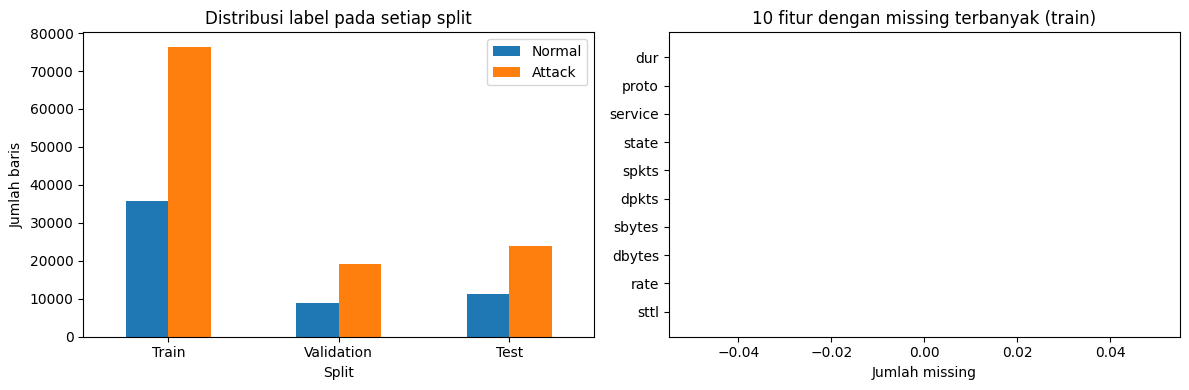

Tidak ada penghapusan outlier otomatis dan tidak ada oversampling sebelum split.


In [6]:
missing_df = pd.DataFrame({
    "Fitur": feature_cols,
    "Missing Train": [int(X_train[c].isna().sum()) for c in feature_cols],
    "Missing Validation": [int(X_val[c].isna().sum()) for c in feature_cols],
    "Missing Test": [int(X_test[c].isna().sum()) for c in feature_cols],
})
missing_df["% Missing Train"] = (100 * missing_df["Missing Train"] / len(X_train)).round(3)
missing_df = missing_df.sort_values("Missing Train", ascending=False)
display(missing_df.head(15))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_summary.set_index("Split")[["Normal", "Attack"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Distribusi label pada setiap split")
axes[0].set_ylabel("Jumlah baris")
axes[0].legend(loc="best")

plot_missing = missing_df.head(10).iloc[::-1]
axes[1].barh(plot_missing["Fitur"], plot_missing["Missing Train"])
axes[1].set_title("10 fitur dengan missing terbanyak (train)")
axes[1].set_xlabel("Jumlah missing")
plt.tight_layout()
plt.show()

print("Tidak ada penghapusan outlier otomatis dan tidak ada oversampling sebelum split.")

## E. Pipeline preprocessing — fit hanya pada training

| Tipe | Penanganan missing | Transformasi |
|---|---|---|
| Numerik | Median (nilai tengah dari **train**) | `StandardScaler` (nilai berbasis mean dan standar deviasi **train**) |
| Kategorikal | Modus (nilai paling sering pada **train**) | `OneHotEncoder(handle_unknown='ignore')` |

*One-hot encoding* mengubah kategori teks menjadi beberapa kolom indikator 0/1. `handle_unknown='ignore'` memastikan kategori baru yang muncul di validation/test tidak menyebabkan error. Model berbasis pohon tidak wajib memakai standardisasi, tetapi standardisasi membantu bila hasil preprocessing juga digunakan untuk model berbasis jarak atau linear.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse
import joblib

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:  # scikit-learn versi lama
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

transformers = []
if num_cols:
    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    transformers.append(("numerik", num_pipeline, num_cols))
if cat_cols:
    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ])
    transformers.append(("kategorikal", cat_pipeline, cat_cols))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop", sparse_threshold=1.0)

# Bagian ini yang terpenting untuk mencegah leakage:
X_train_ready = preprocessor.fit_transform(X_train)  # HANYA train yang dipakai fit
X_val_ready = preprocessor.transform(X_val)          # transform tanpa fit ulang
X_test_ready = preprocessor.transform(X_test)       # transform tanpa fit ulang

# Semua output disimpan sebagai sparse CSR agar format konsisten dan hemat memori.
def as_csr(mat):
    return mat.tocsr() if sparse.issparse(mat) else sparse.csr_matrix(mat)

X_train_ready = as_csr(X_train_ready)
X_val_ready = as_csr(X_val_ready)
X_test_ready = as_csr(X_test_ready)

new_feature_names = preprocessor.get_feature_names_out()
print("Shape training setelah preprocessing  :", X_train_ready.shape)
print("Shape validation setelah preprocessing:", X_val_ready.shape)
print("Shape testing setelah preprocessing   :", X_test_ready.shape)
print("\nContoh 20 nama fitur hasil encoding:")
print(new_feature_names[:20].tolist())

Shape training setelah preprocessing  : (112217, 192)
Shape validation setelah preprocessing: (28055, 192)
Shape testing setelah preprocessing   : (35069, 192)

Contoh 20 nama fitur hasil encoding:
['numerik__dur', 'numerik__spkts', 'numerik__dpkts', 'numerik__sbytes', 'numerik__dbytes', 'numerik__rate', 'numerik__sttl', 'numerik__dttl', 'numerik__sload', 'numerik__dload', 'numerik__sloss', 'numerik__dloss', 'numerik__sinpkt', 'numerik__dinpkt', 'numerik__sjit', 'numerik__djit', 'numerik__swin', 'numerik__stcpb', 'numerik__dtcpb', 'numerik__dwin']


## F. Validasi hasil preprocessing

Kriteria keluaran yang benar:

1. Jumlah **baris** train/validation/test tidak berubah akibat transformasi.
2. Jumlah **kolom** pada ketiga matriks sama.
3. Tidak ada nilai `NaN` atau tak hingga pada hasil transformasi.
4. `label`/`attack_cat`/`id` tidak ikut sebagai fitur.
5. Encoding dan scaling dipelajari dari train saja.

**Catatan:** hasil transformasi `sparse` berisi angka, bukan DataFrame yang dapat langsung dipanggil dengan `.head()`.

In [8]:
assert X_train_ready.shape[0] == len(y_train)
assert X_val_ready.shape[0] == len(y_val)
assert X_test_ready.shape[0] == len(y_test)
assert X_train_ready.shape[1] == X_val_ready.shape[1] == X_test_ready.shape[1]
assert len(new_feature_names) == X_train_ready.shape[1]
for name, m in (("Train", X_train_ready), ("Validation", X_val_ready), ("Test", X_test_ready)):
    if not np.isfinite(m.data).all():
        raise ValueError(f"Masih ada NaN/Inf pada output {name}.")

print("✅ Semua pemeriksaan preprocessing lulus.")
print("Dimensi final:", X_train_ready.shape[1], "fitur")
print("Memori CSR training (perkiraan MB):", round((X_train_ready.data.nbytes + X_train_ready.indices.nbytes + X_train_ready.indptr.nbytes)/1e6, 2))

preview_cols = new_feature_names[:min(12, len(new_feature_names))]
preview = pd.DataFrame(X_train_ready[:5, :len(preview_cols)].toarray(), columns=preview_cols)
display(preview.round(3))

✅ Semua pemeriksaan preprocessing lulus.
Dimensi final: 192 fitur
Memori CSR training (perkiraan MB): 57.01


,numerik__dur,numerik__spkts,numerik__dpkts,numerik__sbytes,numerik__dbytes,numerik__rate,numerik__sttl,numerik__dttl,numerik__sload,numerik__dload,numerik__sloss,numerik__dloss
0,-0.209,-0.130,-0.164,-0.050,-0.100,1.440,0.723,-0.720,0.343,-0.279,-0.074,-0.126
1,0.150,-0.074,-0.096,-0.047,-0.097,-0.577,0.723,1.561,-0.389,-0.278,-0.045,-0.108
2,-0.209,-0.130,-0.164,-0.049,-0.100,1.440,0.723,-0.720,0.413,-0.279,-0.074,-0.126
3,-0.208,-0.018,-0.011,-0.028,-0.084,-0.533,-1.443,-0.457,-0.355,1.342,0.028,-0.001
4,-0.209,-0.130,-0.164,-0.049,-0.100,2.449,0.723,-0.720,0.814,-0.279,-0.074,-0.126


## G. Menyimpan hasil preprocessing (untuk tahap modelling berikutnya)

Hasil disimpan ke folder `Hasil_Preprocessing_UNSW_NB15`:

- `preprocessor.joblib`: objek transformasi yang **sudah di-fit pada train**, bisa dipakai kembali untuk data baru;
- `X_train.npz`, `X_val.npz`, `X_test.npz`: fitur hasil preprocessing berformat sparse CSR;
- `y_train.csv`, `y_val.csv`, `y_test.csv`: label asli sesuai urutan masing-masing matriks;
- `feature_names.csv`, `metadata.json`, `laporan_kualitas_data.csv`, `ringkasan_split.csv`, `ringkasan_missing.csv`: dokumentasi dan audit;
- ZIP untuk memudahkan pengunduhan (opsional, ukuran dapat besar).

**Penting:** `.npz` adalah format matriks hasil preprocessing, **bukan** Jupyter Notebook. Notebook adalah file `.ipynb` yang sedang dibuka.

In [9]:
# Hanya simpan artefak dari perhitungan saat ini.
joblib.dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib")
quality_df.to_csv(OUTPUT_DIR / "laporan_kualitas_data.csv", index=False)
split_summary.to_csv(OUTPUT_DIR / "ringkasan_split.csv", index=False)
missing_df.to_csv(OUTPUT_DIR / "ringkasan_missing.csv", index=False)
pd.DataFrame({"feature_name": new_feature_names}).to_csv(OUTPUT_DIR / "feature_names.csv", index=False)

for name, y in (("train", y_train), ("val", y_val), ("test", y_test)):
    y.to_frame(name="label").to_csv(OUTPUT_DIR / f"y_{name}.csv", index=False)

if SAVE_TRANSFORMED_DATA:
    for name, x in (("train", X_train_ready), ("val", X_val_ready), ("test", X_test_ready)):
        sparse.save_npz(OUTPUT_DIR / f"X_{name}.npz", x, compressed=True)

metadata = {
    "dataset": "UNSW-NB15",
    "kaggle_handle": KAGGLE_HANDLE if DATA_SOURCE == "kaggle" else None,
    "training_source_file": str(TRAIN_FILE),
    "testing_source_file": str(TEST_FILE) if TEST_FILE else None,
    "split_method": split_method,
    "random_state": RANDOM_STATE,
    "target": TARGET,
    "target_classes": {"0": "Normal", "1": "Attack"},
    "dropped_as_features": sorted(EXCLUDE_FEATURES & set(train_df.columns)),
    "dropped_all_missing_features": all_missing_cols,
    "n_features_before": len(feature_cols),
    "n_features_after": int(X_train_ready.shape[1]),
    "numeric_columns": num_cols,
    "categorical_columns": cat_cols,
    "counts": {"train": len(y_train), "validation": len(y_val), "test": len(y_test)},
    "matrix_format": "csr_sparse_npz",
    "note": "fit pada training saja; validation dan testing hanya transform",
}
with open(OUTPUT_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Output disimpan:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f" - {path.name:34s} {path.stat().st_size / 1e6:8.2f} MB")
print("\nFile ZIP akan dibuat di akhir notebook, setelah ringkasan tersimpan.")

Output disimpan:
 - X_test.npz                             3.20 MB
 - X_train.npz                           10.22 MB
 - X_val.npz                              2.56 MB
 - feature_names.csv                      0.00 MB
 - laporan_kualitas_data.csv              0.00 MB
 - metadata.json                          0.00 MB
 - preprocessor.joblib                    0.01 MB
 - ringkasan_missing.csv                  0.00 MB
 - ringkasan_split.csv                    0.00 MB
 - y_test.csv                             0.07 MB
 - y_train.csv                            0.22 MB
 - y_val.csv                              0.06 MB

File ZIP akan dibuat di akhir notebook, setelah ringkasan tersimpan.


### G.1 Contoh menggunakan artefak di notebook modelling lain

Jalankan kode berikut setelah file output dipindahkan/diunggah ke lokasi yang sesuai:

```python
from scipy import sparse
import pandas as pd
import joblib

folder = "/content/Hasil_Preprocessing_UNSW_NB15"
X_train = sparse.load_npz(f"{folder}/X_train.npz")
y_train = pd.read_csv(f"{folder}/y_train.csv")["label"]

# Untuk data baru yang masih mentah (bentuk kolom sama seperti input training):
preprocessor = joblib.load(f"{folder}/preprocessor.joblib")
# X_new_ready = preprocessor.transform(X_new_mentah)
```

**Jangan melakukan `fit_transform()` ulang pada validation/test.** Jangan pula melatih scaler/encoder baru dengan data testing.

## H. Penjelasan otomatis untuk laporan tugas

Uraian di bawah dihitung berdasarkan hasil eksekusi sebenarnya. Kamu bisa menggunakannya sebagai dasar penjelasan kelas, lalu menyesuaikan dengan materi dosen.

In [10]:
missing_train_count = int(X_train.isna().sum().sum())
missing_val_count = int(X_val.isna().sum().sum())
missing_test_count = int(X_test.isna().sum().sum())

report = f"**1. Data awal dan pemeriksaan kualitas.** Dataset memiliki {len(source_train):,} baris training sumber"
report += (f" dan {len(source_test):,} baris testing sumber." if source_test is not None else ". Tidak tersedia CSV testing terpisah.")
report += f" Pemeriksaan menemukan {int(source_train.duplicated().sum()):,} baris duplikat persis pada file training, yang **tidak dihapus otomatis**. Target `label` divalidasi agar hanya bernilai 0 (Normal) dan 1 (Attack).\n\n"
report += f"**2. Pembagian data.** Terdapat {len(y_train):,} data train, {len(y_val):,} data validation, dan {len(y_test):,} data test. Pembagian data dilakukan sebelum mempelajari statistik untuk imputasi dan scaling.\n\n"
report += f"**3. Seleksi dan pembersihan fitur.** Dari dataset dipakai {len(feature_cols)} fitur input, terdiri atas {len(num_cols)} fitur numerik dan {len(cat_cols)} fitur kategorikal. Kolom `id`, `attack_cat`, dan `label` dikecualikan bila tersedia. Sebelum imputasi, terdapat {missing_train_count:,} nilai hilang pada train, {missing_val_count:,} pada validation, serta {missing_test_count:,} pada test setelah normalisasi nilai yang tidak valid.\n\n"
report += f"**4. Transformasi.** Fitur numerik diimputasi dengan median dan distandardisasi menggunakan statistik **training**. Fitur kategorikal diimputasi dengan nilai paling sering dan diubah menjadi variabel indikator melalui one-hot encoding. Jumlah fitur setelah encoding adalah **{X_train_ready.shape[1]}**.\n\n"
report += "**5. Validasi.** Jumlah fitur sama pada train, validation, dan test. Seluruh nilai hasil preprocessing terverifikasi berhingga (tidak ada NaN/Inf). Data test tidak digunakan untuk melakukan fit, sehingga risiko data leakage pada tahap preprocessing diminimalkan.\n\n"
report += "**Kesimpulan.** Hasil preprocessing telah siap untuk pelatihan serta evaluasi model. Tahap ini sendiri **belum** menunjukkan akurasi, precision, recall, atau F1-score karena metrik tersebut baru dihitung setelah modelling."

display(Markdown(report))
(OUTPUT_DIR / "Penjelasan_Preprocessing.md").write_text(report, encoding="utf-8")
if CREATE_ZIP:
    zip_path = Path(shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR))
    print("\n✅ ZIP untuk diunduh:", zip_path, "|", round(zip_path.stat().st_size / 1e6, 2), "MB")

**1. Data awal dan pemeriksaan kualitas.** Dataset memiliki 175,341 baris training sumber. Tidak tersedia CSV testing terpisah. Pemeriksaan menemukan 0 baris duplikat persis pada file training, yang **tidak dihapus otomatis**. Target `label` divalidasi agar hanya bernilai 0 (Normal) dan 1 (Attack).

**2. Pembagian data.** Terdapat 112,217 data train, 28,055 data validation, dan 35,069 data test. Pembagian data dilakukan sebelum mempelajari statistik untuk imputasi dan scaling.

**3. Seleksi dan pembersihan fitur.** Dari dataset dipakai 42 fitur input, terdiri atas 39 fitur numerik dan 3 fitur kategorikal. Kolom `id`, `attack_cat`, dan `label` dikecualikan bila tersedia. Sebelum imputasi, terdapat 0 nilai hilang pada train, 0 pada validation, serta 0 pada test setelah normalisasi nilai yang tidak valid.

**4. Transformasi.** Fitur numerik diimputasi dengan median dan distandardisasi menggunakan statistik **training**. Fitur kategorikal diimputasi dengan nilai paling sering dan diubah menjadi variabel indikator melalui one-hot encoding. Jumlah fitur setelah encoding adalah **192**.

**5. Validasi.** Jumlah fitur sama pada train, validation, dan test. Seluruh nilai hasil preprocessing terverifikasi berhingga (tidak ada NaN/Inf). Data test tidak digunakan untuk melakukan fit, sehingga risiko data leakage pada tahap preprocessing diminimalkan.

**Kesimpulan.** Hasil preprocessing telah siap untuk pelatihan serta evaluasi model. Tahap ini sendiri **belum** menunjukkan akurasi, precision, recall, atau F1-score karena metrik tersebut baru dihitung setelah modelling.


✅ ZIP untuk diunduh: /content/Hasil_Preprocessing_UNSW_NB15.zip | 15.82 MB


## I. Kesimpulan dan catatan untuk pengumpulan

**Preprocessing mencakup:** pemeriksaan label, audit missing/duplikat, pemisahan data, pemilihan fitur, imputasi, encoding, standardisasi, validasi output, dan ekspor hasil. **Modelling berbeda:** modelling memakai hasil preprocessing untuk melatih algoritma klasifikasi dan menghitung metrik prediksi.

Untuk mengumpulkan tugas, pilih **File → Save a copy in Drive** atau **File → Download → Download .ipynb**. Pastikan semua output sel tampil setelah **Runtime → Run all**. Jika KaggleHub tidak dapat diakses, gunakan metode manual tanpa mengubah logika preprocessing.

> Catatan metodologis: penghapusan outlier/duplikasi maupun penanganan ketidakseimbangan kelas **tidak otomatis dilakukan**, karena dapat mengubah makna serangan dan distribusi data. Jika diperlukan untuk eksperimen, terapkan **hanya pada train** dengan alasan yang dapat dipertanggungjawabkan.